# Exercise 2 — Analysing a dataset with pandas

In this exercise you analyse a dataset of divorced couples in the municipality of Xalapa, Mexico, registered between 2000 and 2015 [1]. The column names have been translated to English; the values (such as occupations) are in Spanish.

Exercises on lecture 2: loading, cleaning, selecting, calculating, summarising, combining and plotting.

Put `divorces_2000-2015_translated.csv` and `Comp_matrix.csv` in a folder `data` next to this notebook. Hints are folded away. After every step, check whether the result makes sense: Jupyter Variables and Data Wrangler help.

[1] https://datos.gob.mx/busca/dataset/registro-civil

## 1. Setup

In [1]:
# Install libraries (only needed once per virtual environment)
%pip install numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. A first look at the data

### 2.1 Load the dataset
Load `data/divorces_2000-2015_translated.csv` into `df_divorce` and show the first 10 rows.

In [5]:
df_divorce = pd.read_csv('data/divorces_2000-2015_translated.csv') 
df_divorce.head(10) # Load your dataset here

,Divorce_date,Type_of_divorce,Nationality_partner_man,DOB_partner_man,Place_of_birth_partner_man,Birth_municipality_of_partner_man,Birth_federal_partner_man,Birth_country_partner_man,Age_partner_man,Residence_municipality_partner_man,...,Marriage_certificate_municipality,Marriage_certificate_federal,Level_of_education_partner_man,Employment_status_partner_man,Level_of_education_partner_woman,Employment_status_partner_woman,Marriage_duration,Marriage_duration_months,Num_Children,Custody
0,9/6/06,Necesario,MEXICANA,18/12/75,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,30.0,XALAPA,...,XALAPA,VERACRUZ,SECUNDARIA,OBRERO,SECUNDARIA,EMPLEADO,5.0,NaN,1.0,NaN
1,1/2/00,Voluntario,MEXICANA,NaN,NaN,NaN,NaN,NaN,47.0,NaN,...,XALAPA,VERACRUZ,PREPARATORIA,ESTABLECIMIENTO,PREPARATORIA,EMPLEADO,NaN,NaN,NaN,NaN
2,1/2/05,Necesario,MEXICANA,22/2/55,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,49.0,NaN,...,XALAPA,VERACRUZ,PREPARATORIA,OBRERO,NaN,TRABAJADOR POR CUENTA PROPIA EN VIA PUBLICA,NaN,NaN,NaN,NaN
3,1/2/06,Necesario,MEXICANA,20/1/64,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,42.0,XALAPA,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PREPARATORIA,EMPLEADO,18.0,NaN,2.0,MADRE
4,1/2/06,Necesario,MEXICANA,30/10/75,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,30.0,COATEPEC,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PREPARATORIA,NO TRABAJA,7.0,NaN,2.0,MADRE
5,1/2/06,Necesario,MEXICANA,28/3/73,COATEPEC,COATEPEC,VERACRUZ,MEXICO,32.0,XALAPA,...,XALAPA,VERACRUZ,SECUNDARIA,EMPLEADO,SECUNDARIA,NO TRABAJA,11.0,NaN,2.0,MADRE
6,1/2/07,Necesario,MEXICANA,13/12/70,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,36.0,XALAPA,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PROFESIONAL,NO TRABAJA,15.0,NaN,2.0,MADRE
7,1/2/07,Necesario,MEXICANA,17/2/75,DISTRITO FEDERAL,DISTRITO FEDERAL,DISTRITO FEDERAL,MEXICO,31.0,XALAPA,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PROFESIONAL,EMPLEADO,6.0,NaN,1.0,MADRE
8,1/2/08,Voluntario,MEXICANA,2/12/76,CIUDAD MANTE,CIUDAD MANTE,TAMAULIPAS,MEXICO,31.0,CIUDAD VALLES,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PROFESIONAL,NO TRABAJA,1.0,7.0,NaN,NaN
9,1/2/08,Voluntario,MEXICANA,17/11/76,LOS MOCHIS,LOS MOCHIS,SINALOA,MEXICO,31.0,XALAPA,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PROFESIONAL,EMPLEADO,7.0,11.0,NaN,NaN


### 2.2 Shape
How many rows and columns are there? You should find 4923 rows and 41 columns.

In [7]:
shape = df_divorce.shape
print(f"The dataset has {shape[0]} rows and {shape[1]} columns.")

The dataset has 4923 rows and 41 columns.


### 2.3 Column names
Print the column names: you will need them throughout.

In [36]:
for column in df_divorce.columns:
    print(f"Column '{column}' has {df_divorce[column].isnull().sum()} missing values.")

Column 'Divorce_date' has 0 missing values.
Column 'Type_of_divorce' has 0 missing values.
Column 'Nationality_partner_man' has 1 missing values.
Column 'DOB_partner_man' has 381 missing values.
Column 'Place_of_birth_partner_man' has 126 missing values.
Column 'Birth_municipality_of_partner_man' has 129 missing values.
Column 'Birth_federal_partner_man' has 128 missing values.
Column 'Birth_country_partner_man' has 127 missing values.
Column 'Age_partner_man' has 107 missing values.
Column 'Residence_municipality_partner_man' has 324 missing values.
Column 'Residence_federal_partner_man' has 323 missing values.
Column 'Residence_country_partner_man' has 324 missing values.
Column 'Monthly_income_partner_man_peso' has 1419 missing values.
Column 'Occupation_partner_man' has 529 missing values.
Column 'Place_of_residence_partner_man' has 321 missing values.
Column 'Nationality_partner_woman' has 3 missing values.
Column 'DOB_partner_woman' has 452 missing values.
Column 'DOB_registratio

### 2.4 Statistics
Compute statistics of the numeric columns. Any strange minimum or maximum values?

In [10]:
for column in df_divorce.columns:
    if pd.api.types.is_numeric_dtype(df_divorce[column]):
        print(f"Column '{column}' has a minimum value of {df_divorce[column].min()}.")
        print(f"Column '{column}' has a maximum value of {df_divorce[column].max()}.")

Column 'Age_partner_man' has a minimum value of 19.0.
Column 'Age_partner_man' has a maximum value of 91.0.
Column 'Monthly_income_partner_man_peso' has a minimum value of 2.4.
Column 'Monthly_income_partner_man_peso' has a maximum value of 3150242.0.
Column 'Age_partner_woman' has a minimum value of 17.0.
Column 'Age_partner_woman' has a maximum value of 84.0.
Column 'Monthly_income_partner_woman_peso' has a minimum value of 3.5.
Column 'Monthly_income_partner_woman_peso' has a maximum value of 708652.0.
Column 'Marriage_duration' has a minimum value of 1.0.
Column 'Marriage_duration' has a maximum value of 61.0.
Column 'Marriage_duration_months' has a minimum value of 0.0.
Column 'Marriage_duration_months' has a maximum value of 93.0.
Column 'Num_Children' has a minimum value of 1.0.
Column 'Num_Children' has a maximum value of 10.0.


## 3. Ages at divorce

### 3.1 Select columns
Make a DataFrame `df_ages` with only `'Age_partner_man'`, `'Age_partner_woman'` and `'Marriage_duration'`.

In [16]:
df_ages = df_divorce[['Age_partner_man', 'Age_partner_woman', 'Marriage_duration']].copy()
df_ages.head(100)

,Age_partner_man,Age_partner_woman,Marriage_duration
0,30.0,22.0,5.0
1,47.0,41.0,NaN
2,49.0,57.0,NaN
3,42.0,NaN,18.0
4,30.0,27.0,7.0
...,...,...,...
95,32.0,28.0,5.0
96,27.0,23.0,3.0
97,31.0,26.0,5.0
98,38.0,36.0,15.0


### 3.2 Other rows
Look at the last rows and at a few random rows.

In [17]:
#look at last 10 rows of df_ages
df_ages.tail(10)

,Age_partner_man,Age_partner_woman,Marriage_duration
4913,36.0,29.0,4.0
4914,56.0,52.0,31.0
4915,34.0,32.0,2.0
4916,40.0,37.0,17.0
4917,51.0,51.0,25.0
4918,35.0,34.0,3.0
4919,30.0,32.0,1.0
4920,59.0,56.0,35.0
4921,54.0,48.0,33.0
4922,53.0,41.0,4.0


### 3.3 Missing values
Some values are missing (`NaN`). How many per column?

<details>
<summary><b>Hint</b></summary>

`df.isna().sum()`

</details>

In [19]:
for column in df_ages.columns:
    print(f"Column '{column}' has {df_ages[column].isnull().sum()} missing values.")

Column 'Age_partner_man' has 107 missing values.
Column 'Age_partner_woman' has 151 missing values.
Column 'Marriage_duration' has 235 missing values.


### 3.4 Remove missing values
Keep only the rows where all three values are known.

<details>
<summary><b>Hint</b></summary>

`.dropna()`

</details>

In [ ]:
df_ages_corrected = df_ages.dropna() # Drop rows with missing values in df_ages
for column in df_ages_corrected.columns:
    print(f"Column '{column}' has {df_ages_corrected[column].isnull().sum()} missing values.")

Column 'Age_partner_man' has 0 missing values.
Column 'Age_partner_woman' has 0 missing values.
Column 'Marriage_duration' has 0 missing values.


### 3.5 How many rows are left?
How many rows did you lose?

In [22]:
print(f"The corrected dataset has {df_ages_corrected.shape[0]} rows and {df_ages_corrected.shape[1]} columns.")

The corrected dataset has 4495 rows and 3 columns.


### 3.6 Oldest age at divorce
Compute the maximum of every column at once.

In [23]:
# maximum and minimum values for each column in the corrected dataset
for column in df_ages_corrected.columns:
    print(f"Column '{column}' has a minimum value of {df_ages_corrected[column].min()}.")
    print(f"Column '{column}' has a maximum value of {df_ages_corrected[column].max()}.")

Column 'Age_partner_man' has a minimum value of 19.0.
Column 'Age_partner_man' has a maximum value of 91.0.
Column 'Age_partner_woman' has a minimum value of 17.0.
Column 'Age_partner_woman' has a maximum value of 84.0.
Column 'Marriage_duration' has a minimum value of 1.0.
Column 'Marriage_duration' has a maximum value of 61.0.


### 3.7 Only the men
Now only for the men.

In [26]:
# column 'Age_partner_man' has a minimum value of 18.0
for column in df_ages_corrected.columns:
    if column == 'Age_partner_man':
        print(f"Column '{column}' has a minimum value of {df_ages_corrected[column].min()}.")
        print(f"Column '{column}' has a maximum value of {df_ages_corrected[column].max()}.")

Column 'Age_partner_man' has a minimum value of 19.0.
Column 'Age_partner_man' has a maximum value of 91.0.


### 3.8 Youngest, mean and median
Compute the minimum, mean and median of every column.

In [28]:
for column in df_ages_corrected.columns:
    # compute the mean and standard deviation for each column
    mean = df_ages_corrected[column].mean()
    std = df_ages_corrected[column].std()  
    print(f"Column '{column}' has a mean of {mean:.2f} and a standard deviation of {std:.2f}.")
    #compute the minimum and median for each column
    minimum = df_ages_corrected[column].min()
    median = df_ages_corrected[column].median()
    print(f"Column '{column}' has a minimum of {minimum} and a median of {median}.")

Column 'Age_partner_man' has a mean of 39.36 and a standard deviation of 10.31.
Column 'Age_partner_man' has a minimum of 19.0 and a median of 38.0.
Column 'Age_partner_woman' has a mean of 36.95 and a standard deviation of 9.86.
Column 'Age_partner_woman' has a minimum of 17.0 and a median of 35.0.
Column 'Marriage_duration' has a mean of 11.47 and a standard deviation of 9.13.
Column 'Marriage_duration' has a minimum of 1.0 and a median of 9.0.


### 3.9 Histogram of the ages
Plot the age distributions of men and women in one histogram, with a legend and labelled axes.

<details>
<summary><b>Hint</b></summary>

`bins` sets the number of bars, `alpha` the transparency; `label=...` and `plt.legend()` make the legend.

</details>

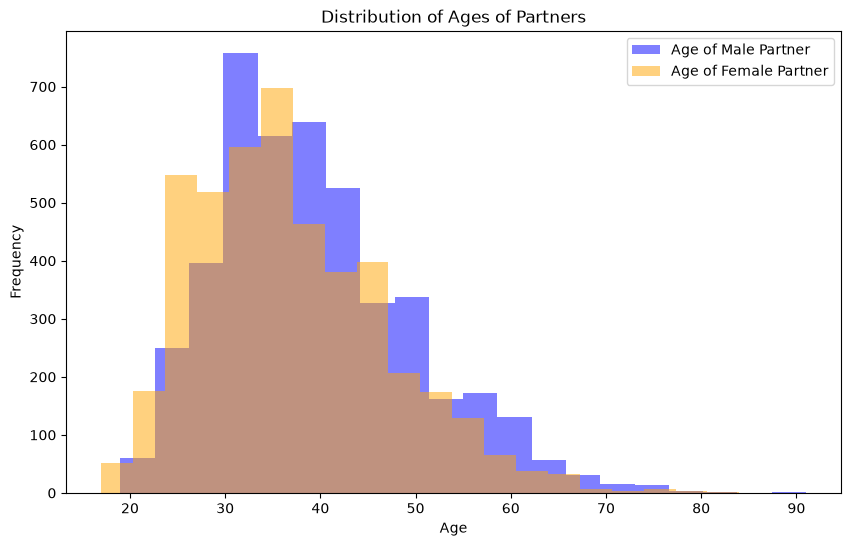

In [30]:
plt.figure(figsize=(10, 6))
plt.hist(df_ages_corrected['Age_partner_man'], bins=20, alpha=0.5, label='Age of Male Partner', color='blue')
plt.hist(df_ages_corrected['Age_partner_woman'], bins=20, alpha=0.5, label='Age of Female Partner', color='orange')
plt.title('Distribution of Ages of Partners')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend()
plt.show()

### 3.10 Side by side
Plot the two distributions next to each other in two subplots.

<details>
<summary><b>Hint</b></summary>

`plt.subplot(1, 2, 1)` selects the first of 1 × 2 plots. `plt.tight_layout()` stops labels from overlapping.

</details>

C:\Users\mathi\AppData\Local\Temp\ipykernel_32388\2024863788.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
C:\Users\mathi\AppData\Local\Temp\ipykernel_32388\2024863788.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


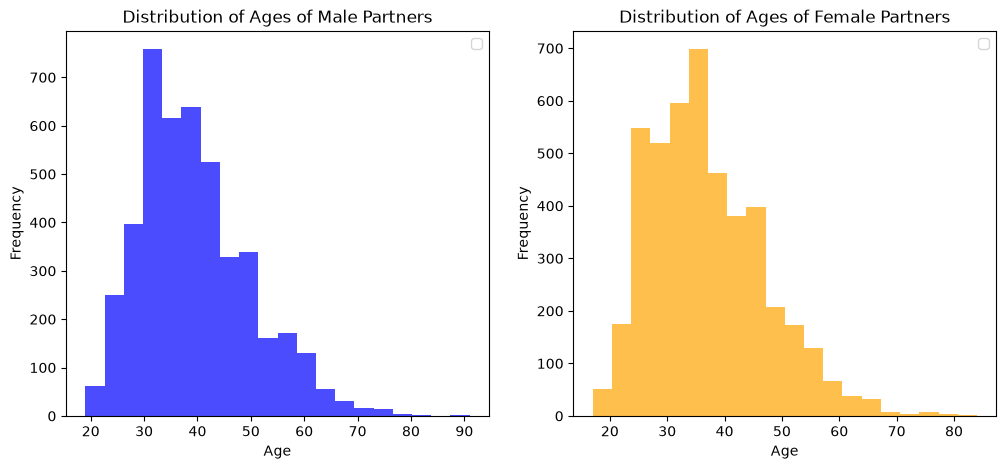

In [31]:
# now, plot the distrubution of men and women in two subplots next to each other
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df_ages_corrected['Age_partner_man'], bins=20, alpha=0.7, color='blue')
plt.title('Distribution of Ages of Male Partners')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df_ages_corrected['Age_partner_woman'], bins=20, alpha=0.7, color='orange')
plt.title('Distribution of Ages of Female Partners')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend()
plt.show()

### 3.11 Length of the marriages
Plot the distribution of the marriage durations.

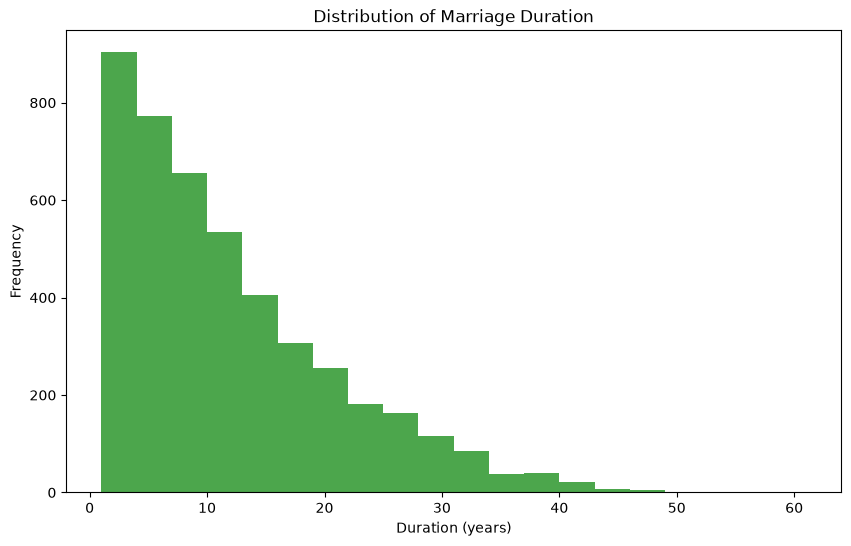

In [32]:
# now plot the distribution of marriage duration
plt.figure(figsize=(10, 6))
plt.hist(df_ages_corrected['Marriage_duration'], bins=20, alpha=0.7, color='green')
plt.title('Distribution of Marriage Duration')
plt.xlabel('Duration (years)')
plt.ylabel('Frequency')
plt.show()

### 3.12 Long marriages
What percentage of the marriages lasted longer than 20 years?

<details>
<summary><b>Hint</b></summary>

A condition gives `True` or `False` per row, and `True` counts as 1. So `.mean()` of a condition gives the fraction of rows where it is `True`.

</details>

In [ ]:
marriage_longer_than_20 = df_ages_corrected[df_ages_corrected['Marriage_duration'] > 20]
print(f"There are {marriage_longer_than_20.shape[0]} marriages longer than 20 years in the corrected dataset.")
print(f"The average marriage duration for these cases is {marriage_longer_than_20['Marriage_duration'].mean():.2f} years.")
print(marriage_longer_than_20.mean())

There are 742 marriages longer than 20 years in the corrected dataset.
The average marriage duration for these cases is 27.84 years.
Age_partner_man      52.836927
Age_partner_woman    50.365229
Marriage_duration    27.843666
dtype: float64


### 3.13 Age at marriage
Compute the age at marriage of men and women and plot both in one histogram. Also print the youngest ages.

Youngest man's age at marriage: 9 years
Youngest woman's age at marriage: 6 years


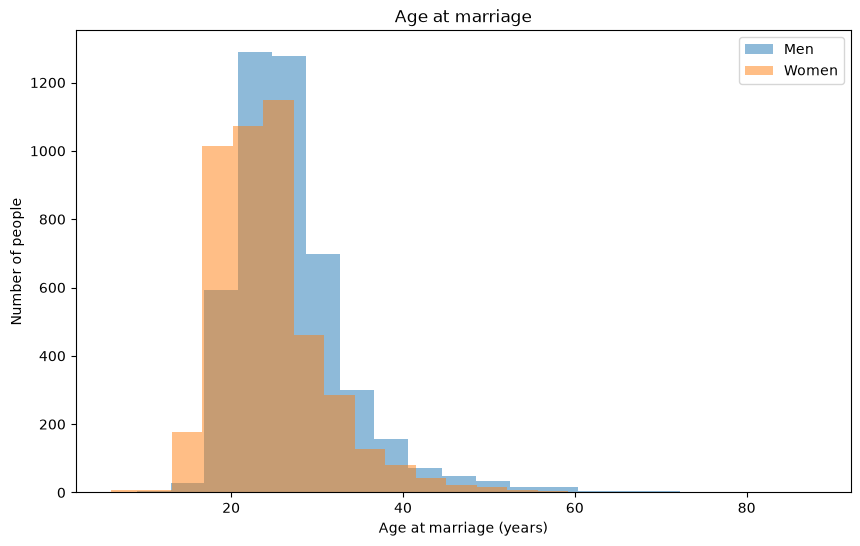

In [37]:
date_columns = [
    "Date_of_marriage",
    "DOB_partner_man",
    "DOB_partner_woman"
]

for date_column in date_columns:
    df_divorce[date_column] = pd.to_datetime(
        df_divorce[date_column],
        format="%d/%m/%y",
        errors="coerce"
    )

# Correct DOBs that were interpreted as dates after the marriage
for dob_column in ["DOB_partner_man", "DOB_partner_woman"]:
    parsed_as_future = df_divorce[dob_column] > df_divorce["Date_of_marriage"]
    df_divorce.loc[parsed_as_future, dob_column] = (
        df_divorce.loc[parsed_as_future, dob_column] - pd.DateOffset(years=100)
    )

def age_at_marriage(dob, marriage_date):
    years = marriage_date.dt.year - dob.dt.year
    birthday_not_reached = (
        (marriage_date.dt.month < dob.dt.month)
        | (
            (marriage_date.dt.month == dob.dt.month)
            & (marriage_date.dt.day < dob.dt.day)
        )
    )
    return (years - birthday_not_reached.astype("Int64")).astype("Int64")

df_divorce["Age_at_marriage_man"] = age_at_marriage(
    df_divorce["DOB_partner_man"], df_divorce["Date_of_marriage"]
)
df_divorce["Age_at_marriage_woman"] = age_at_marriage(
    df_divorce["DOB_partner_woman"], df_divorce["Date_of_marriage"]
)

print("Youngest man's age at marriage:",
      df_divorce["Age_at_marriage_man"].min(), "years")
print("Youngest woman's age at marriage:",
      df_divorce["Age_at_marriage_woman"].min(), "years")

plt.figure(figsize=(10, 6))
plt.hist(df_divorce["Age_at_marriage_man"].dropna(),
         bins=20, alpha=0.5, label="Men")
plt.hist(df_divorce["Age_at_marriage_woman"].dropna(),
         bins=20, alpha=0.5, label="Women")

plt.xlabel("Age at marriage (years)")
plt.ylabel("Number of people")
plt.title("Age at marriage")
plt.legend()
plt.show()

### 3.14 Is the data correct?
Do you think all data was entered correctly?

*Your answer:*

Lol, I surely don't hope so.

## 4. Age difference

### 4.1 A new column
Add a column `'Age_difference'` to `df_ages`: age of the man minus age of the woman. Keep the sign: it tells who is older.

In [39]:
df_ages["Age_difference"] = (
    df_divorce["DOB_partner_woman"] - df_divorce["DOB_partner_man"]
).dt.days / 365.25

df_ages.head()

,Age_partner_man,Age_partner_woman,Marriage_duration,Age_difference
0,30.0,22.0,5.0,7.058179
1,47.0,41.0,NaN,NaN
2,49.0,57.0,NaN,-7.926078
3,42.0,NaN,18.0,NaN
4,30.0,27.0,7.0,2.954141


### 4.2 Who is older?
On average, who is older?

In [40]:
woman_older = 0
man_older = 0
for age_diff in df_ages["Age_difference"]:
    if age_diff < 0:
        # negative means woman is older than man, positive means man is older than woman
        woman_older +=1
    else:
        man_older +=1

if woman_older > man_older:
    print(f"There are more cases where the woman is older than the man ({woman_older}) than cases where the man is older than the woman ({man_older}).")
else:
    print(f"There are more cases where the man is older than the woman ({man_older}) than cases where the woman is older than the man ({woman_older}).")

There are more cases where the man is older than the woman (3606) than cases where the woman is older than the man (1317).


### 4.3 Largest differences
What is the largest age difference when the man is older? And when the woman is older?

<details>
<summary><b>Hint</b></summary>

When the woman is older, the difference is negative.

</details>

In [42]:
#print age difference max and min
print(f"Maximum age difference (man older): {df_ages['Age_difference'].max()}")
print(f"Minimum age difference (woman older): {df_ages['Age_difference'].min()}")

Maximum age difference (man older): 40.11772758384668
Minimum age difference (woman older): -47.441478439425055


### 4.4 Histogram
Plot the distribution of the age differences.

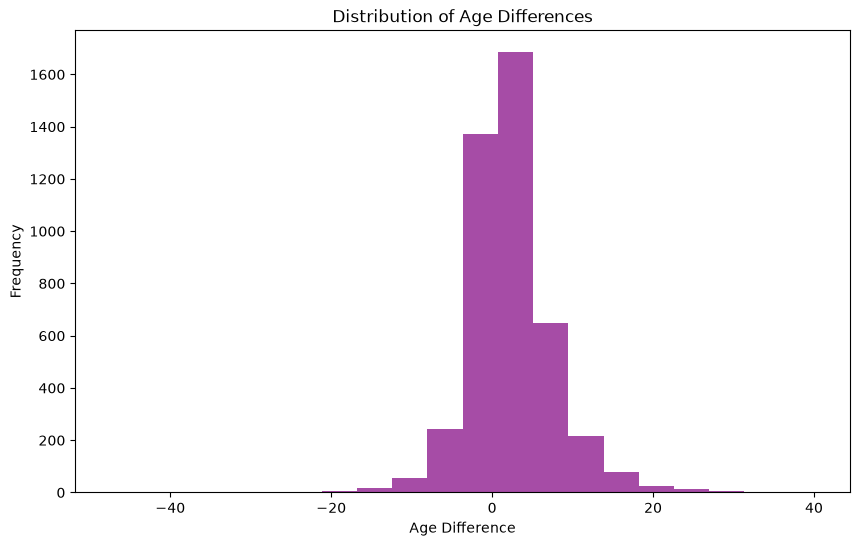

In [43]:
plt.figure(figsize=(10, 6))
plt.hist(df_ages["Age_difference"].dropna(), bins=20, alpha=0.7, color='purple')
plt.xlabel('Age Difference')
plt.ylabel('Frequency')
plt.title('Distribution of Age Differences')
plt.show()

### 4.5 A conclusion?
Most divorced couples have a small age difference. Can we conclude from this data that a small age difference leads to a higher chance of divorce?

*Your answer:*

Lol, no we can't.

## 5. Occupations

### 5.1 Select columns
Make a DataFrame `df_occupations` with the occupations and monthly incomes of men and women.

In [44]:
df_occupations = df_divorce[["Occupation_partner_man", "Occupation_partner_woman", "Monthly_income_partner_man_peso", "Monthly_income_partner_woman_peso"]].copy()
df_occupations.head()

,Occupation_partner_man,Occupation_partner_woman,Monthly_income_partner_man_peso,Monthly_income_partner_woman_peso
0,PINTOR,EMPLEADA,2000.0,1800.0
1,NaN,NaN,NaN,NaN
2,MEDICO,JUBILADA,NaN,NaN
3,EMPLEADO,COMERCIANTE,6000.0,5000.0
4,MEDICO,AMA DE CASA,18000.0,NaN


### 5.2 Number of occupations
How many different occupations are there for men, and for women?

<details>
<summary><b>Hint</b></summary>

`.nunique()` counts the distinct values in a column.

</details>

In [45]:
for occupation_column in ["Occupation_partner_man", "Occupation_partner_woman"]:
    print(f"Unique occupations for {occupation_column}:")
    print(df_occupations[occupation_column].value_counts())
    print("\n")

Unique occupations for Occupation_partner_man:
Occupation_partner_man
EMPLEADO               2352
COMERCIANTE             299
PROFESOR                132
MAESTRO                  89
MEDICO                   87
                       ... 
FUNCIONARIO PRIVADO       1
IMPRESOR                  1
MENTOR                    1
MANIOBRISTA               1
CAPITAN DE CORBETA        1
Name: count, Length: 221, dtype: int64


Unique occupations for Occupation_partner_woman:
Occupation_partner_woman
EMPLEADA              1886
AMA DE CASA            550
LABORES DOMESTICAS     325
MAESTRA                215
COMERCIANTE            174
                      ... 
COSMETOLOGA              1
ADMINISTRATIVO           1
MENTORA                  1
PROFESORA JUBILADA       1
PREPARATORIA             1
Name: count, Length: 156, dtype: int64




### 5.3 Most common occupation
What is the most common occupation for men, and for women?

In [47]:
#print most common occupation for men and women
most_common_men = df_occupations["Occupation_partner_man"].value_counts().idxmax
most_common_women = df_occupations["Occupation_partner_woman"].value_counts().idxmax

print(f"The most common occupation for men is: {most_common_men()}")
print(f"The most common occupation for women is: {most_common_women()}")

The most common occupation for men is: EMPLEADO
The most common occupation for women is: EMPLEADA


### 5.4 Top 10
Show the 10 most common occupations for both, with how often each occurs.

In [48]:
#print top 10 most common occupations for men and women with counts
print("Top 10 most common occupations for men:")
print(df_occupations["Occupation_partner_man"].value_counts().head(10))

print("\nTop 10 most common occupations for women:")
print(df_occupations["Occupation_partner_woman"].value_counts().head(10))

Top 10 most common occupations for men:
Occupation_partner_man
EMPLEADO       2352
COMERCIANTE     299
PROFESOR        132
MAESTRO          89
MEDICO           87
CHOFER           86
ARQUITECTO       75
ABOGADO          73
DESEMPLEADO      66
ING.             66
Name: count, dtype: int64

Top 10 most common occupations for women:
Occupation_partner_woman
EMPLEADA              1886
AMA DE CASA            550
LABORES DOMESTICAS     325
MAESTRA                215
COMERCIANTE            174
PROFESORA              136
ESTUDIANTE             134
EMPLEADO                74
EDUCADORA               64
DOCENTE                 59
Name: count, dtype: int64


## 6. Income per occupation

### 6.1 Average income per occupation
Compute the average monthly income per occupation, for men and for women.

In [50]:
#compute average monthly income for men and women per occupation
# average_income_men = df_occupations.groupby("Occupation_partner_man")["Monthly_income_partner_man_peso"].mean().sort_values(ascending=False)
# average_income_women = df_occupations.groupby("Occupation_partner_woman")["Monthly_income_partner_woman_peso"].mean().sort_values(ascending=False)  

# print("Average monthly income for men per occupation:")
# print(average_income_men.head(10))  

# print("\nAverage monthly income for women per occupation:")
# print(average_income_women.head(10))  


men_by_occupation = (
    df_occupations.groupby("Occupation_partner_man")
    .agg(
        average_income=("Monthly_income_partner_man_peso", "mean"),
        number_of_people=("Occupation_partner_man", "size")
    )
    .sort_values("average_income", ascending=False)
)

women_by_occupation = (
    df_occupations.groupby("Occupation_partner_woman")
    .agg(
        average_income=("Monthly_income_partner_woman_peso", "mean"),
        number_of_people=("Occupation_partner_woman", "size")
    )
    .sort_values("average_income", ascending=False)
)

print("Men:")
print(men_by_occupation.head(10))

print("\nWomen:")
print(women_by_occupation.head(10))


Men:
                              average_income  number_of_people
Occupation_partner_man                                        
MUSICO                         144984.434783                27
PROFESOR DE EDUCACION FISICA    75000.000000                 1
ORTODONCISTA                    40000.000000                 1
PENSIONADO                      30519.772727                38
LIC. EN EDUCACION               30000.000000                 1
SECRETARIO                      30000.000000                 1
ALMACENISTA                     26937.000000                 1
GINECOLOGO                      25000.000000                 1
INVESTIGADOR                    25000.000000                 1
CAPITAN DE ALTURA               25000.000000                 1

Women:
                                 average_income  number_of_people
Occupation_partner_woman                                         
SERVIDOR PUBLICO                        28000.0                 1
CANTADORA PUBLICA                

### 6.2 Best paid occupations
Which 5 occupations have the highest average income, for men and for women?

In [51]:
# already did this

### 6.3 Average and count in one table
Make one DataFrame for men and one for women with, per occupation, the average income and the number of people. Name the occupation column `'Occupation'` in both, so you can merge them in 6.4.

<details>
<summary><b>Hint</b></summary>

`.agg()` computes several results per group:

```python
df_occupations.groupby('Occupation_partner_man').agg(
    average_income_man=('Monthly_income_partner_man_peso', 'mean'),
    count_man=('Monthly_income_partner_man_peso', 'count'),
)
```

After `groupby`, the occupation is the index. `.reset_index()` turns it back into a column, and `.rename(columns={'old': 'new'})` renames it.

</details>

In [59]:
# now let's make one dataframe for men and one for women per occupation, the average income and the number of people
df_occupations_men = (
    df_occupations.groupby("Occupation_partner_man")
    .agg(
        average_income=("Monthly_income_partner_man_peso", "mean"),
        number_of_people=("Occupation_partner_man", "size")
    )
    .sort_values("average_income", ascending=False)
    .rename_axis("Occupation")
    .reset_index()
)

print(df_occupations_men.head(10))

df_occupations_women = (
    df_occupations.groupby("Occupation_partner_woman")
    .agg(
        average_income=("Monthly_income_partner_woman_peso", "mean"),
        number_of_people=("Occupation_partner_woman", "size")
    )
    .sort_values("average_income", ascending=False)
    .rename_axis("Occupation")
    .reset_index()
)

print("\nWomen:")
print(df_occupations_women.head(10))


                     Occupation  average_income  number_of_people
0                        MUSICO   144984.434783                27
1  PROFESOR DE EDUCACION FISICA    75000.000000                 1
2                  ORTODONCISTA    40000.000000                 1
3                    PENSIONADO    30519.772727                38
4             LIC. EN EDUCACION    30000.000000                 1
5                    SECRETARIO    30000.000000                 1
6                   ALMACENISTA    26937.000000                 1
7                    GINECOLOGO    25000.000000                 1
8                  INVESTIGADOR    25000.000000                 1
9             CAPITAN DE ALTURA    25000.000000                 1

Women:
                        Occupation  average_income  number_of_people
0                 SERVIDOR PUBLICO         28000.0                 1
1                CANTADORA PUBLICA         25000.0                 1
2                    INVESTIGADORA         24000.0         

### 6.4 Merge men and women
Merge the two DataFrames into one row per occupation, and remove rows with missing values.

In [60]:
#now merge those two dataframes on the occupation column, and remove rows with missing values in either dataframe
df_occupations_merged = pd.merge(
    df_occupations_men,
    df_occupations_women,
    left_on="Occupation",
    right_on="Occupation",
    suffixes=("_men", "_women"),
    how="inner"
)
print("\nMerged Data:")
print(df_occupations_merged.head(10))


Merged Data:
            Occupation  average_income_men  number_of_people_men  \
0               MUSICO       144984.434783                    27   
1    LIC. EN EDUCACION        30000.000000                     1   
2      MEDICO FAMILIAR        21000.000000                     1   
3               VENTAS        20000.000000                     1   
4     SERVIDOR PUBLICO        19500.000000                     3   
5          VETERINARIO        18000.000000                     2   
6  FUNCIONARIO PUBLICO        17500.000000                     2   
7      LIC. EN DERECHO        14833.333333                     7   
8           PERIODISTA        13600.000000                     8   
9               MEDICO        13434.968750                    87   

   average_income_women  number_of_people_women  
0              10100.00                       5  
1               5000.00                       1  
2              21000.00                       1  
3              20000.00              

### 6.5 Income difference
Add a column `'Income_difference'` (men minus women) and plot its histogram.

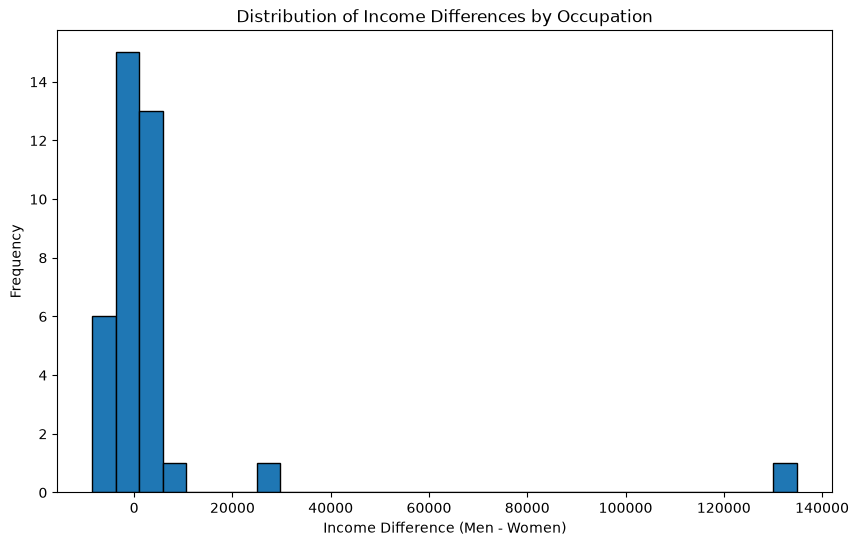

In [61]:
#append a column of Income_difference = average_income_men - average_income_women
df_occupations_merged["Income_difference"] = (
    df_occupations_merged["average_income_men"] - df_occupations_merged["average_income_women"]
)

#plot histogram of income difference
plt.figure(figsize=(10, 6))
plt.hist(df_occupations_merged["Income_difference"], bins=30, edgecolor="black")
plt.xlabel("Income Difference (Men - Women)")
plt.ylabel("Frequency")
plt.title("Distribution of Income Differences by Occupation")
plt.show()

### 6.6 Enough people per occupation?
There is one large outlier. Maybe it comes from an occupation that only one or two people have? Keep only occupations with at least 5 men and at least 5 women, and plot again.

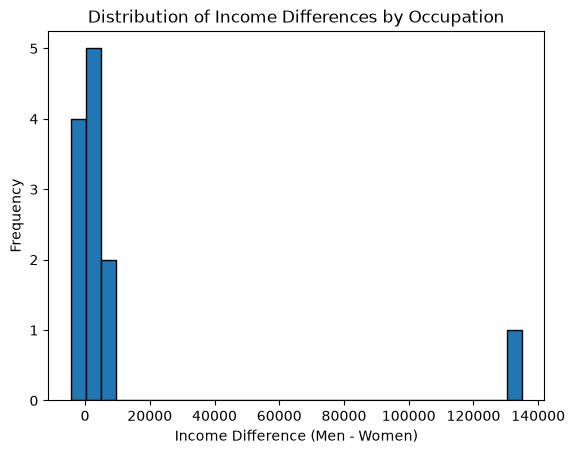

In [62]:
# now make the same plot, but only for occupations with at least 5 men and 5 women
df_occupations_filtered = df_occupations_merged[(df_occupations_merged["number_of_people_men"] >= 5) & (df_occupations_merged["number_of_people_women"] >= 5)]
plt.hist(df_occupations_filtered["Income_difference"], bins=30, edgecolor="black")
plt.xlabel("Income Difference (Men - Women)")
plt.ylabel("Frequency")
plt.title("Distribution of Income Differences by Occupation")
plt.show()

### 6.7 Largest differences
The outlier is still there. Show the 5 occupations where men earn most compared to women, and the 5 where women earn most compared to men.

In [64]:
# print(df_occupations_filtered["Income_difference"].head(5))
# print(df_occupations_filtered["Income_difference"].tail(5))

columns_to_show = ["Occupation", "Income_difference"]

print("Men earn most compared with women:")
print(df_occupations_filtered.nlargest(5, "Income_difference")[columns_to_show])

print("\nWomen earn most compared with men:")
print(df_occupations_filtered.nsmallest(5, "Income_difference")[columns_to_show])


Men earn most compared with women:
           Occupation  Income_difference
0              MUSICO      134884.434783
8          PERIODISTA        8600.000000
7     LIC. EN DERECHO        5191.083333
18        COMERCIANTE        4248.199736
12  CIRUJANO DENTISTA        4000.000000

Women earn most compared with men:
          Occupation  Income_difference
26     PROFESIONISTA       -4430.000000
19  CONTADOR PUBLICO       -1962.500000
20           DOCENTE       -1527.163121
22          DENTISTA       -1433.333333
23        ESTUDIANTE        1231.818182


### 6.8 The outlier
The outlier is in the musicians group (`'MUSICO'`). Find the male musician with the very high income in `df_divorce`. What is his date of birth?

In [69]:
#find the data of birth of the man with the occupation "MUSICO" and the highest income
musicians = df_divorce[
    df_divorce["Occupation_partner_man"] == "MUSICO"
]

highest_income_row = musicians.loc[
    [musicians["Monthly_income_partner_man_peso"].idxmax()]
].copy()

highest_income_row["DOB_partner_man"] = (
    highest_income_row["DOB_partner_man"].dt.strftime("%d/%m/%Y")
)

print(highest_income_row.to_string(index=False))

Divorce_date Type_of_divorce Nationality_partner_man DOB_partner_man Place_of_birth_partner_man Birth_municipality_of_partner_man Birth_federal_partner_man Birth_country_partner_man  Age_partner_man Residence_municipality_partner_man Residence_federal_partner_man Residence_country_partner_man  Monthly_income_partner_man_peso Occupation_partner_man Place_of_residence_partner_man Nationality_partner_woman DOB_partner_woman DOB_registration_date_partner_woman Place_of_birth_partner_woman Birth_municipality_of_partner_woman Birth_federal_partner_woman Birth_country_partner_woman  Age_partner_woman Place_of_residence_partner_woman Residence_municipality_partner_woman Residence_federal_partner_woman Residence_country_partner_woman Occupation_partner_woman  Monthly_income_partner_woman_peso Date_of_marriage Marriage_certificate_place Marriage_certificate_municipality Marriage_certificate_federal Level_of_education_partner_man Employment_status_partner_man Level_of_education_partner_woman Empl

## 7. Income distribution

### 7.1 Select and clean
Make a DataFrame `df_incomes` with the monthly incomes of men and women, without missing values.

In [72]:
# make dataframe of df_incomes with montly incomes of men and women without missing values
df_incomes = df_divorce[["Monthly_income_partner_man_peso", "Monthly_income_partner_woman_peso"]].dropna()
print(df_incomes.head(10))

    Monthly_income_partner_man_peso  Monthly_income_partner_woman_peso
0                            2000.0                             1800.0
3                            6000.0                             5000.0
9                            6000.0                             6000.0
10                           5000.0                             5000.0
11                          12000.0                            12000.0
12                           6000.0                            10000.0
15                          20000.0                               15.0
18                           5600.0                             4500.0
19                           3500.0                             4000.0
22                          12000.0                             7000.0


### 7.2 Histogram
Plot the income distributions of men and women in one histogram.

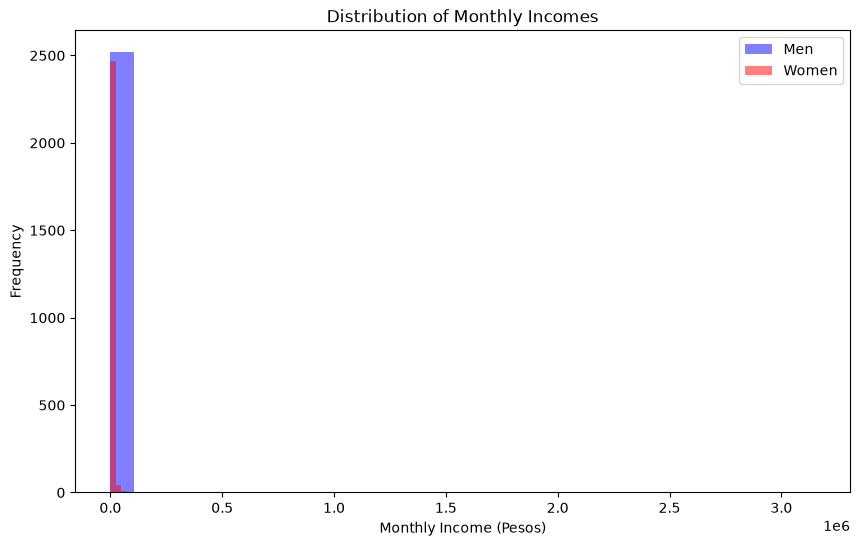

In [73]:
plt.figure(figsize=(10, 6))
plt.hist(df_incomes["Monthly_income_partner_man_peso"], bins=30, alpha=0.5, label="Men", color='blue')
plt.hist(df_incomes["Monthly_income_partner_woman_peso"], bins=30, alpha=0.5, label="Women", color='red')
plt.xlabel("Monthly Income (Pesos)")
plt.ylabel("Frequency")
plt.title("Distribution of Monthly Incomes")
plt.legend()
plt.show()

### 7.3 A log scale
Most incomes are squeezed together on the left. Plot them on a log scale.

<details>
<summary><b>Hint</b></summary>

`plt.xscale('log')` sets a log scale. On a log scale, bars of equal width look strange. Use bins of equal width on the log scale:
`bins=np.logspace(start_power, stop_power, number_of_bins)`, for example `np.logspace(1, 7, 50)` for 50 bins from 10¹ to 10⁷. A log scale cannot show 0: incomes of 0 are left out.

</details>

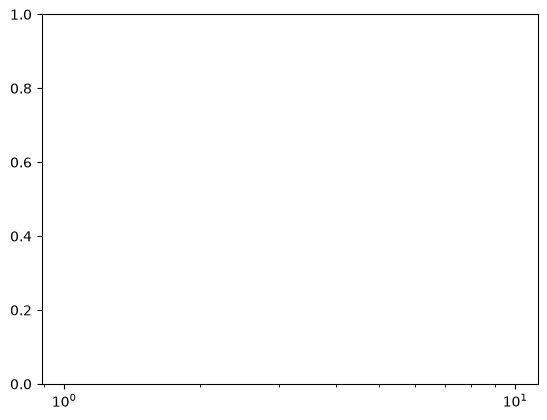

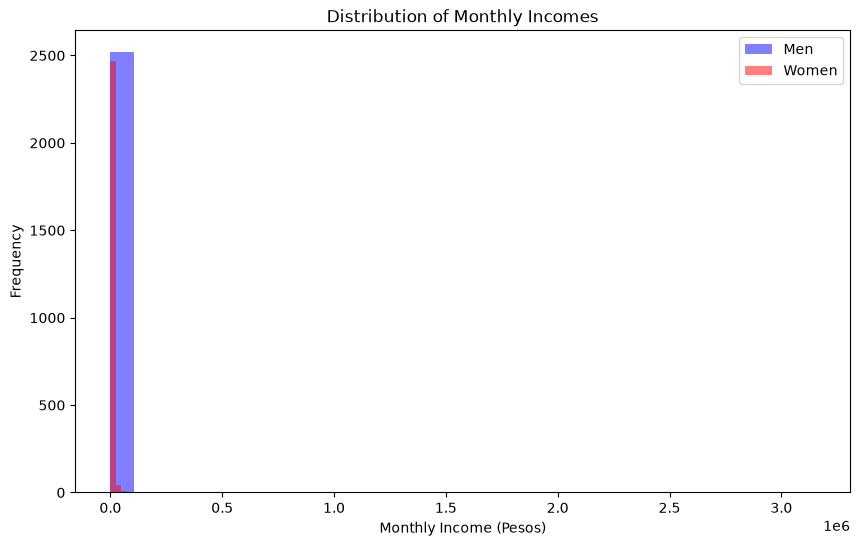

In [74]:
#plot them now on a log scale
plt.xscale('log')
plt.figure(figsize=(10, 6))
plt.hist(df_incomes["Monthly_income_partner_man_peso"], bins=30, alpha=0.5, label="Men", color='blue')
plt.hist(df_incomes["Monthly_income_partner_woman_peso"], bins=30, alpha=0.5, label="Women", color='red')
plt.xlabel("Monthly Income (Pesos)")
plt.ylabel("Frequency")
plt.title("Distribution of Monthly Incomes")
plt.legend()
plt.show()

### 7.4 Income difference per couple
Compute the income difference of every couple (man minus woman): minimum, maximum and median.

### 7.5 Percentages
What percentage of the couples differ more than 1000 pesos in income, in either direction? What percentage earn exactly the same?

<details>
<summary><b>Hint</b></summary>

`.abs()` gives the absolute value.

</details>

## 8. Does astrology predict divorce?

### 8.1 Dates of birth
Make a DataFrame `df_DOB` with the dates of birth of men and women, without missing values.

### 8.2 Text to dates
The dates of birth are text such as `22/2/55` (day/month/two-digit year). Convert both columns to dates.

<details>
<summary><b>Hint</b></summary>

`pd.to_datetime(column, format='%d/%m/%y')`

</details>

### 8.3 Check the dates
Print the latest date of birth of men and of women. Does that make sense?

<details>
<summary><b>Hint</b></summary>

Remember lecture 2: with a two-digit year, Python reads `00`–`68` as 2000–2068 and `69`–`99` as 1969–1999.

</details>

### 8.4 Fix the century
Write a function `fix_century(date)` that moves dates in the future back by 100 years. Apply it to both columns and check again.

<details>
<summary><b>Hint</b></summary>

`pd.Timestamp.today()` is today, and `date - pd.DateOffset(years=100)` is 100 years earlier.

</details>

### 8.5 Day and month
A zodiac sign only needs the day and month. Add the columns `'day_man'`, `'month_man'`, `'day_woman'` and `'month_woman'`.

<details>
<summary><b>Hint</b></summary>

`.dt.day` and `.dt.month`

</details>

### 8.6 Zodiac signs
The function below returns the zodiac sign for a day and month.

In [ ]:
def zodiac_sign(day, month):
    if month == 12:
        return 'Sagittarius' if day < 22 else 'Capricorn'
    elif month == 1:
        return 'Capricorn' if day < 20 else 'Aquarius'
    elif month == 2:
        return 'Aquarius' if day < 19 else 'Pisces'
    elif month == 3:
        return 'Pisces' if day < 21 else 'Aries'
    elif month == 4:
        return 'Aries' if day < 20 else 'Taurus'
    elif month == 5:
        return 'Taurus' if day < 21 else 'Gemini'
    elif month == 6:
        return 'Gemini' if day < 21 else 'Cancer'
    elif month == 7:
        return 'Cancer' if day < 23 else 'Leo'
    elif month == 8:
        return 'Leo' if day < 23 else 'Virgo'
    elif month == 9:
        return 'Virgo' if day < 23 else 'Libra'
    elif month == 10:
        return 'Libra' if day < 23 else 'Scorpio'
    elif month == 11:
        return 'Scorpio' if day < 22 else 'Sagittarius'

This applies `zodiac_sign` to every couple. It needs two columns at once, so `.apply()` runs on the whole DataFrame, once per row (`axis=1`). `lambda row: ...` is a short function without a name.

In [ ]:
df_DOB['Zodiac_sign_man'] = df_DOB.apply(lambda row: zodiac_sign(row['day_man'], row['month_man']), axis=1)
df_DOB['Zodiac_sign_woman'] = df_DOB.apply(lambda row: zodiac_sign(row['day_woman'], row['month_woman']), axis=1)
df_DOB.head()

### 8.7 The compatibility table
`data/Comp_matrix.csv` holds the compatibility of every pair of zodiac signs, from https://numerologysign.com/zodiac-compatibility/. Load it into `df_compatibility`.

### 8.8 How many rows?
How many rows does it have, and how many do you expect?

*Your answer:*

### 8.9 Combine the signs
The compatibility table has a column `'Zodiac_combination'` with both signs in one text. Add the same column, in exactly the same format, to `df_DOB`.

<details>
<summary><b>Hint</b></summary>

Text columns can be joined with `+`.

</details>

### 8.10 Merge
Add the `'Compatibility_rate'` to every couple by merging. Did you lose any couples?

### 8.11 Median
Compute the median compatibility rate of all 144 combinations in `df_compatibility`. Half of the combinations score above it.

### 8.12 Good or bad match
Label every couple as a `'good'` match (rate above the median) or a `'bad'` one, in a column `'Match'`.

<details>
<summary><b>Hint</b></summary>

`np.where(condition, value_if_true, value_if_false)`

</details>

### 8.13 Percentages
What percentage of the divorced couples is a good match? Compare with 50%.

### 8.14 Conclusion
Do the predictions of the astrology website make sense for this dataset?

*Your answer:*

## 9. Bonus: translate the occupations

The occupations are in Spanish. The `deep-translator` library can translate them with Google Translate. It needs internet and uses an unofficial connection to Google Translate, which can be slow or stop working: that is why this part is optional.

In [ ]:
%pip install deep-translator

In [ ]:
from deep_translator import GoogleTranslator

translator = GoogleTranslator(source='es', target='en')


def translate_word(word):
    try:
        return translator.translate(word.lower()).lower()
    except Exception as error:      # if translating fails, report it and continue
        print(f'Could not translate {word}: {error}')
        return None

### 9.1 Translate
Add a column `'Occupation_EN'` with the English occupations to `df_income_comparison_filtered` (from 6.6).